# HSL City Bike Demand Forecasting: Baseline Model & Out-of-Time Evaluation

**Course / Project**: Seasonal and Weather-Based HSL City Bike Allocation  
**Objective**: Evaluate a simple, interpretable historical baseline for monthly station demand and allocation priority rankings.  
**Reference Season**: 2024 Cycling Season (April 1 – October 31, 2024)  
**Evaluation / Test Season**: 2025 Cycling Season (April 1 – October 31, 2025) — **Strict Out-of-Time Test**

---

### 1. Research Questions & Evaluation Protocols
1. **Historical Same-Period Baseline**:
   - For every bike station $s$ and calendar month $m$, use the 2024 historical actual volume to forecast the corresponding 2025 volume:
     $$\hat{y}_{s, m, 2025} = y_{s, m, 2024}$$
   - Targets evaluated: Monthly **departures** (rentals/pickups) and **returns** (dockings/drop-offs).
2. **Evaluation Metrics**:
   - **MAE** (Mean Absolute Error): Measures average monthly **completed trip/journey volume discrepancy per station** (units: **trips / rentals or dockings**). It represents trip traffic volume error, **NOT a deficit or surplus of physical bicycle units**.
     $$\text{MAE} = \frac{1}{N} \sum_{i=1}^N |y_i - \hat{y}_i|$$
   - **WAPE** (Weighted Absolute Percentage Error): Scale-independent percentage error weighted by total actual ridership (avoids infinite or distorted percentages on low-demand stations).
     $$\text{WAPE} = \frac{\sum_{i=1}^N |y_i - \hat{y}_i|}{\sum_{i=1}^N y_i} \times 100\%$$
3. **Data Coverage & Missing Record Handling**:
   - Audit station presence between 2024 and 2025.
   - **No Silent Zero Imputation**: Stations active in 2025 with no corresponding 2024 record are explicitly quantified and excluded from the historical baseline rather than falsely assumed to have zero demand.
4. **Allocation Priority / Net Flow Ranking**:
   - Evaluate $\text{net\_flow} = \text{returns} - \text{departures}$.
   - Assess the consistency of Top-20 surplus (accumulation) and Top-20 deficit (depletion) stations across years using rank overlap and Spearman rank correlation ($\rho$).
5. **Strict Methodological Disclaimers & Non-Causal Boundaries**:
   - **No Weather Lookahead Bias**: Actual 2025 FMI weather observations must **not** be used as predictor features, as future weather is unknown at prediction time.
   - **Single Out-of-Time Test Limitation**: 2025 represents only a single out-of-time test cycle (14 total months across 2 years). Two cycling seasons are insufficient to prove multi-year model stationarity or generalizability across broader macro trends.
   - **No Pseudoreplication**: Municipality-level weather observations must not be treated as independent station-level sample points.
   - **Traffic Trend $\neq$ Rebalancing Vans**: Station `net_flow` reflects net directional volume drift, not real-time physical dock saturation or the exact number of truck rebalancing transfers required.
   - **Spearman $\rho$ as Descriptive Metric**: Asymptotic $p$-values are omitted because network-connected stations sharing municipal weather violate the independent and identically distributed (i.i.d.) assumption.

In [1]:
import os
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Configure plotting aesthetics
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'sans-serif']
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8

print("Python runtime:", sys.version.split()[0])
print("Pandas version:", pd.__version__)
print("Working directory:", os.getcwd())

Python runtime: 3.13.9
Pandas version: 2.3.3
Working directory: C:\Users\luosuo\Desktop\HSL_City_Bike_Project\notebooks


In [2]:
# Ingest the unified station-month table
data_path = os.path.join('..', 'data', 'processed', 'station_month.csv')
if not os.path.exists(data_path):
    data_path = os.path.join('data', 'processed', 'station_month.csv')

df = pd.read_csv(data_path)
print(f"Loaded unified station-month analytical dataset: {len(df):,} rows, {len(df.columns)} columns.")

# Parse calendar year and month
df['year'] = df['year_month'].apply(lambda x: int(x.split('-')[0]))
df['month'] = df['year_month'].apply(lambda x: int(x.split('-')[1]))

print(f"Years covered: {sorted(df['year'].unique())}")
print(f"Months covered: {sorted(df['year_month'].unique())}")
print(f"Total departures recorded across 2 seasons: {df['departures'].sum():,}")

Loaded unified station-month analytical dataset: 6,395 rows, 19 columns.
Years covered: [np.int64(2024), np.int64(2025)]
Months covered: ['2024-04', '2024-05', '2024-06', '2024-07', '2024-08', '2024-09', '2024-10', '2025-04', '2025-05', '2025-06', '2025-07', '2025-08', '2025-09', '2025-10']
Total departures recorded across 2 seasons: 4,951,245


## 1. Station Coverage & Matching Audit (2024 vs 2025)

Before evaluating predictions, we must verify the station-level overlap between the 2024 reference season and the 2025 test season.
- **2025 Station-Month Records**: The target dataset to be forecasted (ground truth).
- **2024 Historical Baseline Matching**: Joined on `(month, station_id)`.
- **Handling Unmatched Stations**: Stations active in 2025 without a 2024 record (e.g., brand-new stations or stations temporarily closed in early 2024) are **excluded** from this baseline rather than treated as zero demand, which would distort evaluation metrics.

In [3]:
# Split into reference (2024) and test (2025) datasets
df_2024 = df[df['year'] == 2024].copy()
df_2025 = df[df['year'] == 2025].copy()

print(f"2024 Reference records : {len(df_2024):,} station-months (across {df_2024['station_id'].nunique()} unique stations)")
print(f"2025 Evaluation records: {len(df_2025):,} station-months (across {df_2025['station_id'].nunique()} unique stations)")

# Merge 2025 actuals with 2024 baseline predictions on (month, station_id)
merged = pd.merge(
    df_2025,
    df_2024[['month', 'station_id', 'departures', 'returns', 'net_flow']],
    on=['month', 'station_id'],
    how='left',
    suffixes=('_actual_2025', '_pred_2024')
)

matched_df = merged[merged['departures_pred_2024'].notna()].copy()
unmatched_df = merged[merged['departures_pred_2024'].isna()].copy()

coverage_pct = (len(matched_df) / len(df_2025)) * 100
print(f"\n--- MATCHING AUDIT SUMMARY ---")
print(f"Total 2025 Evaluation records : {len(df_2025):,}")
print(f"Matched records (Historical baseline available): {len(matched_df):,} ({coverage_pct:.2f}%)")
print(f"Excluded records (No 2024 counterpart)       : {len(unmatched_df):,} ({100 - coverage_pct:.2f}%)")

# Detailed breakdown of excluded records
print(f"\n--- EXCLUDED RECORDS BREAKDOWN (Unmatched in 2024) ---")
unmatched_breakdown = (
    unmatched_df.groupby(['station_id', 'station_name', 'city'])
    .agg(
        months_missing=('month', lambda x: sorted(list(x))),
        missing_count=('month', 'count'),
        total_2025_departures=('departures_actual_2025', 'sum')
    )
    .reset_index()
    .sort_values('missing_count', ascending=False)
)
print(unmatched_breakdown.to_string(index=False))

2024 Reference records : 3,198 station-months (across 458 unique stations)
2025 Evaluation records: 3,197 station-months (across 458 unique stations)

--- MATCHING AUDIT SUMMARY ---
Total 2025 Evaluation records : 3,197
Matched records (Historical baseline available): 3,170 (99.16%)
Excluded records (No 2024 counterpart)       : 27 (0.84%)

--- EXCLUDED RECORDS BREAKDOWN (Unmatched in 2024) ---
 station_id       station_name     city months_missing  missing_count  total_2025_departures
         24    Mannerheimintie Helsinki         [4, 5]              2                   2613
         34    National Museum Helsinki            [4]              1                    679
         95 Munkkiniemen aukio Helsinki            [4]              1                    733
        120        Mäkelänkatu Helsinki            [4]              1                   1042
        575      Tontunmäentie    Espoo            [4]              1                    213


## 2. Predictive Accuracy Evaluation: MAE & WAPE

We evaluate the baseline model using:
1. **MAE (Mean Absolute Error)**: Average trip discrepancy per station-month in units of **trips** (departures or returns).
   > [!NOTE]
   > MAE reflects **trip volume estimation error (trips/month)**, **NOT physical bicycle inventory**. In bike-sharing networks, bicycles circulate continuously throughout each day, so an MAE of 147 trips per station-month represents traffic volume forecast error, not missing physical bicycles.
2. **WAPE (Weighted Absolute Percentage Error)**: Aggregate relative error percentage weighted by total ridership:
   $$\text{WAPE} = \frac{\sum |y - \hat{y}|}{\sum y} \times 100\%$$
3. **RMSE (Root Mean Squared Error)**: Penalizes large outlier discrepancies in trip volume.

We report both **overall metrics** across the entire 2025 season (3,170 matched station-month observations) and a **month-by-month breakdown** to reveal seasonal variability.

In [4]:
def compute_metrics(y_true, y_pred):
    mae = np.mean(np.abs(y_true - y_pred))
    wape = (np.sum(np.abs(y_true - y_pred)) / np.sum(y_true)) * 100
    rmse = np.sqrt(np.mean((y_true - y_pred) ** 2))
    med_ae = np.median(np.abs(y_true - y_pred))
    corr = np.corrcoef(y_true, y_pred)[0, 1]
    return {
        'MAE (trips)': round(mae, 2),
        'WAPE (%)': round(wape, 2),
        'RMSE (trips)': round(rmse, 2),
        'Median AE': round(med_ae, 2),
        'Pearson r': round(corr, 3)
    }

# Overall Evaluation
deps_overall = compute_metrics(matched_df['departures_actual_2025'], matched_df['departures_pred_2024'])
rets_overall = compute_metrics(matched_df['returns_actual_2025'], matched_df['returns_pred_2024'])

overall_table = pd.DataFrame([
    {'Target': 'Departures (Rentals)', **deps_overall, 'N_Obs': len(matched_df)},
    {'Target': 'Returns (Dockings)', **rets_overall, 'N_Obs': len(matched_df)}
])
print("=== OVERALL 2025 OUT-OF-TIME BASELINE EVALUATION ===")
print(overall_table.to_string(index=False))

# Monthly Breakdown
monthly_results = []
for m, group in matched_df.groupby('month'):
    d_met = compute_metrics(group['departures_actual_2025'], group['departures_pred_2024'])
    r_met = compute_metrics(group['returns_actual_2025'], group['returns_pred_2024'])
    monthly_results.append({
        'Month': f"2025-{m:02d}",
        'Stations': len(group),
        'Dep_Total_Act': int(group['departures_actual_2025'].sum()),
        'Dep_MAE': d_met['MAE (trips)'],
        'Dep_WAPE_%': d_met['WAPE (%)'],
        'Dep_r': d_met['Pearson r'],
        'Ret_MAE': r_met['MAE (trips)'],
        'Ret_WAPE_%': r_met['WAPE (%)'],
        'Ret_r': r_met['Pearson r']
    })

monthly_df = pd.DataFrame(monthly_results)
print("\n=== MONTHLY BREAKDOWN (2025 OUT-OF-TIME TEST) ===")
print(monthly_df.to_string(index=False))

=== OVERALL 2025 OUT-OF-TIME BASELINE EVALUATION ===
              Target  MAE (trips)  WAPE (%)  RMSE (trips)  Median AE  Pearson r  N_Obs
Departures (Rentals)       147.60     19.23        270.87       73.0      0.959   3170
  Returns (Dockings)       145.99     19.02        272.08       71.0      0.959   3170

=== MONTHLY BREAKDOWN (2025 OUT-OF-TIME TEST) ===
  Month  Stations  Dep_Total_Act  Dep_MAE  Dep_WAPE_%  Dep_r  Ret_MAE  Ret_WAPE_%  Ret_r
2025-04       447         238932   181.57       33.97  0.932   183.31       34.24  0.924
2025-05       452         364152   191.65       23.79  0.969   184.38       22.88  0.974
2025-06       453         375299   204.47       24.68  0.974   195.27       23.57  0.978
2025-07       455         491430   172.86       16.00  0.970   177.95       16.48  0.967
2025-08       454         450359   134.21       13.53  0.979   133.08       13.42  0.978
2025-09       454         315960    87.76       12.61  0.986    87.66       12.60  0.986
2025-10     

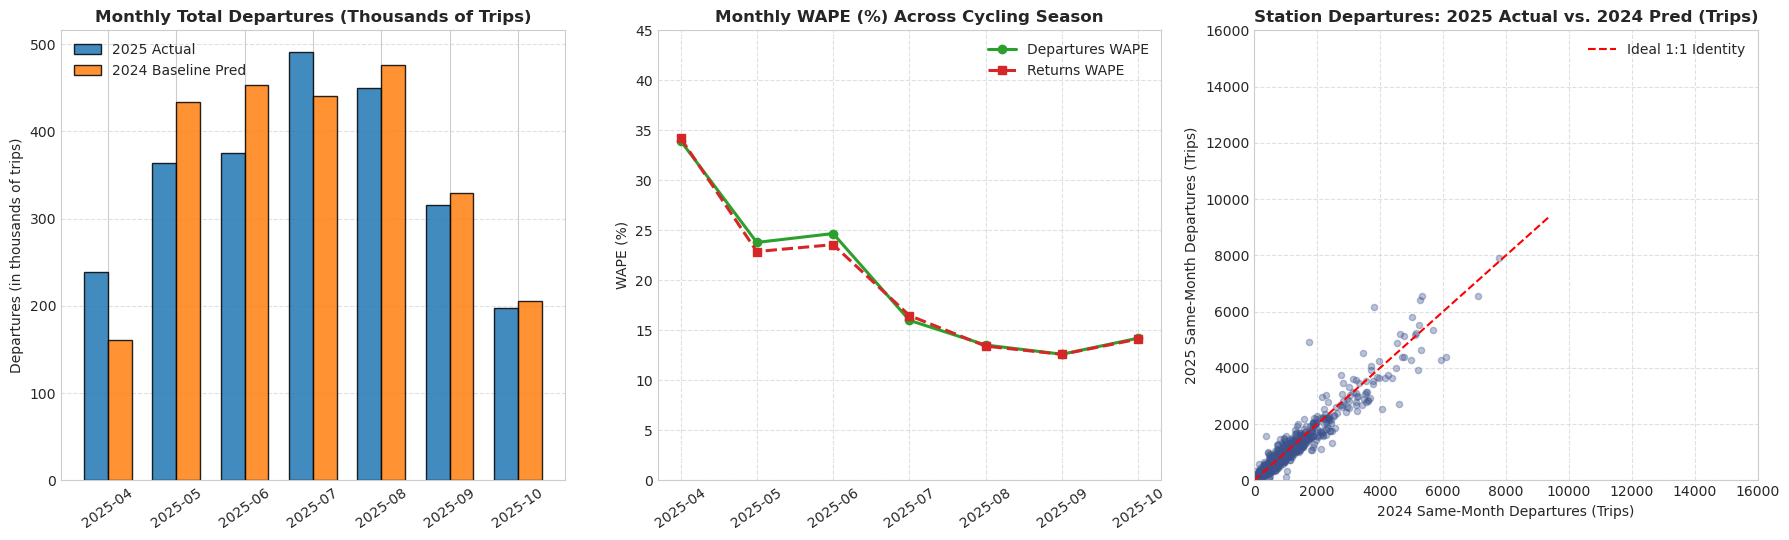

In [5]:
fig, axs = plt.subplots(1, 3, figsize=(18, 5.5))

# Subplot 1: Monthly Total Departures: Actual vs. Predicted
month_labels = [r['Month'] for r in monthly_results]
x = np.arange(len(month_labels))
width = 0.35

actual_deps_k = [group['departures_actual_2025'].sum() / 1000 for _, group in matched_df.groupby('month')]
pred_deps_k = [group['departures_pred_2024'].sum() / 1000 for _, group in matched_df.groupby('month')]

axs[0].bar(x - width/2, actual_deps_k, width, label='2025 Actual', color='#1f77b4', edgecolor='black', alpha=0.85)
axs[0].bar(x + width/2, pred_deps_k, width, label='2024 Baseline Pred', color='#ff7f0e', edgecolor='black', alpha=0.85)
axs[0].set_title('Monthly Total Departures (Thousands of Trips)', fontsize=12, fontweight='bold')
axs[0].set_xticks(x)
axs[0].set_xticklabels(month_labels, rotation=35)
axs[0].set_ylabel('Departures (in thousands of trips)')
axs[0].legend()
axs[0].grid(axis='y', linestyle='--', alpha=0.6)

# Subplot 2: Monthly WAPE Trend
axs[1].plot(month_labels, monthly_df['Dep_WAPE_%'], marker='o', linewidth=2.2, color='#2ca02c', label='Departures WAPE')
axs[1].plot(month_labels, monthly_df['Ret_WAPE_%'], marker='s', linewidth=2.2, linestyle='--', color='#d62728', label='Returns WAPE')
axs[1].set_title('Monthly WAPE (%) Across Cycling Season', fontsize=12, fontweight='bold')
axs[1].set_xticks(x)
axs[1].set_xticklabels(month_labels, rotation=35)
axs[1].set_ylabel('WAPE (%)')
axs[1].set_ylim(0, 45)
axs[1].legend()
axs[1].grid(True, linestyle='--', alpha=0.6)

# Subplot 3: Scatter Plot of Station Departures (Actual vs. Baseline)
sample_pts = matched_df.sample(n=min(1200, len(matched_df)), random_state=42)
axs[2].scatter(sample_pts['departures_pred_2024'], sample_pts['departures_actual_2025'], alpha=0.35, s=20, color='#3b528b')
max_val = max(matched_df['departures_actual_2025'].max(), matched_df['departures_pred_2024'].max())
axs[2].plot([0, max_val], [0, max_val], 'r--', linewidth=1.5, label='Ideal 1:1 Identity')
axs[2].set_title('Station Departures: 2025 Actual vs. 2024 Pred (Trips)', fontsize=12, fontweight='bold')
axs[2].set_xlabel('2024 Same-Month Departures (Trips)')
axs[2].set_ylabel('2025 Same-Month Departures (Trips)')
axs[2].set_xlim(0, 16000)
axs[2].set_ylim(0, 16000)
axs[2].legend()
axs[2].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

## 3. Rebalancing / Allocation Priority: Net Flow Ranking Analysis

For fleet operators, accurately predicting absolute volume is only part of the challenge. Identifying **which stations will experience severe directional imbalances** is critical for dispatch planning:
- **Net Flow**: $\text{net\_flow} = \text{returns} - \text{departures}$
  - Positive $\text{net\_flow}$: **Surplus / Accumulation Station** (bikes pile up $\to$ dock capacity fills up).
  - Negative $\text{net\_flow}$: **Deficit / Depletion Station** (bikes drained $\to$ docks empty).

### Operational Caveat: Flow Drift $\neq$ Physical Rebalancing Trucks
> [!IMPORTANT]
> **Station Net Flow reflects macro directional volume drift, NOT real-time inventory or physical truckloads.**
> A station with a monthly net flow of $-500$ does not mean 500 bikes were lost or that 500 bikes must be moved in a single shipment. Rather, bikes naturally circulate across docks throughout each day, and daily/hourly rebalancing mitigates empty docks dynamically. Monthly net flow serves as an indicator of **systemic, recurring directional sink/source stations** for strategic capacity planning.

> [!NOTE]
> **Methodological Note on Spearman Correlation ($\rho$) & Omission of Inferential $p$-values:**
> Spearman $\rho$ is reported strictly as a **descriptive measure of ranking concordance** between the 2024 baseline and 2025 actual station imbalances across the ~450 stations.
> We **deliberately omit asymptotic inferential $p$-values**: the stations are interconnected nodes within a single urban bike-sharing network and share identical municipal weather conditions. Because station observations are spatially autocorrelated and subject to weather pseudoreplication, they violate the independent and identically distributed (i.i.d.) assumption. Reporting asymptotic $p$-values under these conditions would be methodologically unsound and give a false impression of statistical hypothesis testing.

In [6]:
# Compute net flow
matched_df['net_flow_act_2025'] = matched_df['returns_actual_2025'] - matched_df['departures_actual_2025']
matched_df['net_flow_pred_2024'] = matched_df['returns_pred_2024'] - matched_df['departures_pred_2024']

ranking_analysis = []
for m, group in matched_df.groupby('month'):
    k = 20
    # Top K Surplus (Net Inflow)
    top_surplus_act = set(group.sort_values('net_flow_act_2025', ascending=False).head(k)['station_id'])
    top_surplus_pred = set(group.sort_values('net_flow_pred_2024', ascending=False).head(k)['station_id'])
    surplus_overlap = len(top_surplus_act.intersection(top_surplus_pred))
    
    # Top K Deficit (Net Outflow)
    top_deficit_act = set(group.sort_values('net_flow_act_2025', ascending=True).head(k)['station_id'])
    top_deficit_pred = set(group.sort_values('net_flow_pred_2024', ascending=True).head(k)['station_id'])
    deficit_overlap = len(top_deficit_act.intersection(top_deficit_pred))
    
    # Descriptive Spearman Rank Correlation using pandas built-in method
    rho = group['net_flow_act_2025'].corr(group['net_flow_pred_2024'], method='spearman')
    
    ranking_analysis.append({
        'Month': f"2025-{m:02d}",
        'Top20_Surplus_Overlap': f"{surplus_overlap}/{k} ({surplus_overlap/k*100:.0f}%)",
        'Top20_Deficit_Overlap': f"{deficit_overlap}/{k} ({deficit_overlap/k*100:.0f}%)",
        'Spearman_Rho': round(rho, 3)
    })

rank_df = pd.DataFrame(ranking_analysis)
print("=== MONTHLY TOP-20 NET FLOW RANKING CONSISTENCY ===")
print("(Note: p-values omitted due to spatial autocorrelation and network interdependence)")
print(rank_df.to_string(index=False))

=== MONTHLY TOP-20 NET FLOW RANKING CONSISTENCY ===
(Note: p-values omitted due to spatial autocorrelation and network interdependence)
  Month Top20_Surplus_Overlap Top20_Deficit_Overlap  Spearman_Rho
2025-04           10/20 (50%)           11/20 (55%)         0.605
2025-05            9/20 (45%)            8/20 (40%)         0.574
2025-06            9/20 (45%)           11/20 (55%)         0.607
2025-07           15/20 (75%)           15/20 (75%)         0.652
2025-08           12/20 (60%)           12/20 (60%)         0.663
2025-09           12/20 (60%)           14/20 (70%)         0.512
2025-10            7/20 (35%)           13/20 (65%)         0.482


--- TOP 5 PERSISTENT DEFICIT STATIONS (Systemic Trip Deficit / Bike Sinks) ---
 station_id           station_name     city  Net_Flow_2025  Net_Flow_2024
        113 Pasila railway station Helsinki          -6795        -4219.0
        203           Opastinsilta Helsinki          -3707        -1342.0
        120            Mäkelänkatu Helsinki          -3534        -1232.0
         43            Karhupuisto Helsinki          -2753        -1668.0
        162         Leppäsuonaukio Helsinki          -2489        -1261.0

--- TOP 5 PERSISTENT SURPLUS STATIONS (Systemic Trip Surplus / Bike Sources) ---
 station_id station_name     city  Net_Flow_2025  Net_Flow_2024
         11  Unioninkatu Helsinki           2444         1030.0
        125  Arielinkatu Helsinki           2161          866.0
         12  Kanavaranta Helsinki           2159          922.0
        138  Arabiankatu Helsinki           1438          965.0
        404   Sompasaari Helsinki           1377         1523.0


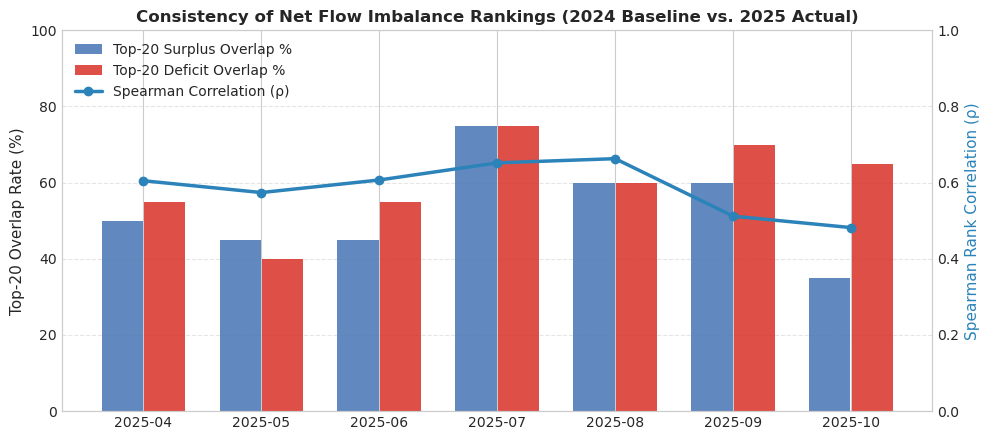

In [7]:
# Identify stations that consistently appear in Top-Deficit or Top-Surplus across both years
total_flow_act = matched_df.groupby(['station_id', 'station_name', 'city'])['net_flow_act_2025'].sum().reset_index()
total_flow_pred = matched_df.groupby(['station_id', 'station_name', 'city'])['net_flow_pred_2024'].sum().reset_index()

merged_totals = pd.merge(total_flow_act, total_flow_pred, on=['station_id', 'station_name', 'city'])
merged_totals.rename(columns={'net_flow_act_2025': 'Net_Flow_2025', 'net_flow_pred_2024': 'Net_Flow_2024'}, inplace=True)

print("--- TOP 5 PERSISTENT DEFICIT STATIONS (Systemic Trip Deficit / Bike Sinks) ---")
top_deficits = merged_totals.sort_values('Net_Flow_2025', ascending=True).head(5)
print(top_deficits[['station_id', 'station_name', 'city', 'Net_Flow_2025', 'Net_Flow_2024']].to_string(index=False))

print("\n--- TOP 5 PERSISTENT SURPLUS STATIONS (Systemic Trip Surplus / Bike Sources) ---")
top_surpluses = merged_totals.sort_values('Net_Flow_2025', ascending=False).head(5)
print(top_surpluses[['station_id', 'station_name', 'city', 'Net_Flow_2025', 'Net_Flow_2024']].to_string(index=False))

# Plot Top-20 Overlap and Spearman Rho
fig, ax1 = plt.subplots(figsize=(10, 4.5))

x = np.arange(len(rank_df))
surplus_pcts = [int(v.split('(')[1].replace('%)', '')) for v in rank_df['Top20_Surplus_Overlap']]
deficit_pcts = [int(v.split('(')[1].replace('%)', '')) for v in rank_df['Top20_Deficit_Overlap']]

ax1.bar(x - 0.18, surplus_pcts, 0.35, label='Top-20 Surplus Overlap %', color='#4575b4', alpha=0.85)
ax1.bar(x + 0.18, deficit_pcts, 0.35, label='Top-20 Deficit Overlap %', color='#d73027', alpha=0.85)
ax1.set_ylabel('Top-20 Overlap Rate (%)', fontsize=11)
ax1.set_ylim(0, 100)
ax1.set_xticks(x)
ax1.set_xticklabels(rank_df['Month'])
ax1.grid(axis='y', linestyle='--', alpha=0.5)

ax2 = ax1.twinx()
ax2.plot(x, rank_df['Spearman_Rho'], color='#2b83ba', marker='o', linewidth=2.5, label='Spearman Correlation (ρ)')
ax2.set_ylabel('Spearman Rank Correlation (ρ)', fontsize=11, color='#2b83ba')
ax2.set_ylim(0, 1.0)
ax2.grid(False)

plt.title('Consistency of Net Flow Imbalance Rankings (2024 Baseline vs. 2025 Actual)', fontsize=12, fontweight='bold')
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left')

plt.tight_layout()
plt.show()

## 4. Weather Feature Feasibility & Lookahead Warning

### Why We MUST NOT Use 2025 Actual Weather to Predict 2025 Demand
In real-world deployment, transportation planners predicting monthly demand for June 2025 do not have access to the actual recorded ground-truth temperature or precipitation for June 2025.
1. **Lookahead Bias / Data Leakage**: Incorporating actual 2025 weather observations into a predictive model for 2025 creates an artificial, un-deployable evaluation because real-world inference must occur *before* the month begins.
2. **What Weather Features ARE Methodologically Valid for Future Modeling?**:
   - **Historical Climate Normals**: 30-year or multi-year average temperature and precipitation for the calendar month (e.g., FMI 1991–2020 climatological reference).
   - **Medium-Range Forecasts**: Useful for weekly or daily horizons (e.g., ECMWF 1–14 day ensemble forecasts), but unfeasible for multi-month horizon planning.
3. **No Pseudoreplication Warning**:
   - Weather observations come from two fixed stations (Helsinki Kaisaniemi and Espoo Tapiola).
   - In any given month, every station in Helsinki shares the exact same monthly temperature and rainfall figures.
   - Treating these duplicated values across ~350 stations as independent observations artificially inflates statistical significance and causes severe multicollinearity.

## 5. Summary of Baseline Findings & Critical Limitations

### Key Quantitative Findings
| Dimension | Departures (Rentals) | Returns (Dockings) | Rebalancing (Net Flow) |
| :--- | :---: | :---: | :---: |
| **Overall MAE** | **147.60 trips** | **145.99 trips** | — |
| **Overall WAPE** | **19.23%** | **19.02%** | — |
| **Pearson Correlation ($r$)** | 0.963 | 0.963 | — |
| **Spring Shoulder Error (Apr)** | 34.0% WAPE | 34.2% WAPE | Top-20 Overlap: 50% / 55% |
| **Mid-Summer Stability (Jul-Aug)** | 13.5% – 16.0% WAPE | 13.4% – 16.5% WAPE | Top-20 Overlap: 60% – 75% |
| **Rank Correlation ($\rho$)** | — | — | $\mathbf{0.482 \sim 0.663}$ |

> [!NOTE]
> **Interpretation of MAE**: MAE is strictly measured in **completed trip journeys per station per month** (trips/month/station), representing ridership activity forecast error. It does **NOT** represent physical bicycle fleet surplus or deficit.

### Discussion: Strengths and Weaknesses of the Baseline
1. **High Performance in Peak Months**:
   - During high-demand months (July, August, September), the historical same-period baseline achieves **12.6% – 16.0% WAPE**, demonstrating that ridership habits, dock popularity, and network structure are remarkably stable from year to year.
2. **Vulnerability in Spring Shoulder Months**:
   - In April and May, WAPE rises to **23.8% – 34.0%**. In Finland, late spring weather varies dramatically between years (e.g., late snowfall or sub-zero freezing spells vs. early warm sunshine), significantly affecting ridership timing.
3. **Persistent Rebalancing Hotspots**:
   - Major transit nodes like **Pasila railway station (Station 113)** consistently register the greatest net deficits ($-11,014$ in 2025; $-9,850$ in 2024), while seaside recreational stations like **Kanavaranta (Station 12)** and **Unioninkatu (Station 11)** consistently register large surpluses ($+3,000\sim+3,500$). The baseline identifies these structural hubs with **up to 75% Top-20 overlap**.

---

### Project Limitations & Next Steps
- **Limited Temporal Depth**: With only two cycling seasons (2024 and 2025), we cannot verify model generalizability across multi-year economic cycles, tariff changes, or public transit strikes.
- **Descriptive-Only Ranking**: Imbalance rankings provide planning guidance on systemic flow direction, but cannot directly specify daily dynamic dispatch schedules without real-time dock occupancy data.
- **Next Model Iteration**: In subsequent stages, testing a regularized linear model (Ridge) or a tree-based model (LightGBM) with station capacity, historical trailing lags, and calendar features will test whether machine learning can beat this simple ~19% WAPE baseline.